In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
from utils_spec import *
import os
from tqdm import tqdm
import json
from datetime import date

In [2]:
# Get the current date
todays_date = date.today()
year = str(todays_date.year)
if todays_date.month < 10:
    month = '0'+str(todays_date.month)
else:
    month = str(todays_date.month)

if todays_date.day < 10:
    day = '0'+str(todays_date.day)
else:
    day = str(todays_date.day)

current_date = year+month+day
directory_name = 'results/'+current_date
if not os.path.isdir(directory_name):
    os.mkdir(directory_name)
    
directory_name

'results/20251216'

In [3]:
remove_slopp = pd.read_excel('RochmanSpectra_ToRemove.xlsx', sheet_name="SLOPPe Remove")

mIRageLibraySpectra_Removed = pd.read_csv('../gloves_contamination/mIRageLibraySpectra_Removed.csv')
mIRageLibraySpectra_Removed.iloc[-1,2] = 'PE_15'

dict_slopp_reb = {'PE':'Polyethylene', 
                  'PP':'Polypropylene', 
                  'PSL':'Polystyrene'}

with open('processed_data/active_data_blank_raman_saturation.json', 'r') as f:
    saturated_wn_dict = json.load(f)

    
ids_sat = list(saturated_wn_dict.keys())

slopp_df = pd.read_csv('processed_data/slopp_data_raman_final_specy.csv')
del slopp_df['Unnamed: 0']
slopp_df.columns = list(np.float64(slopp_df.columns[:-4])) + list(slopp_df.columns[-4:])

slopp_df = slopp_df.query('polymer != "Cotton" and polymer !="Dyed Cellulose"').reset_index(drop=True)
slopp_df.loc[slopp_df['polymer'] == "Polyester",'polymer'] = "Polyethylene Terephthalate"
slopp_df = slopp_df.loc[[x not in np.array(remove_slopp['Example']) for x in slopp_df['id']], :].reset_index(drop=True)

rebecca_raman_df = pd.read_csv('processed_data/rebecca_data_raman_final_specy.csv')
del rebecca_raman_df['Unnamed: 0']
rebecca_raman_df.columns = list(np.float64(rebecca_raman_df.columns[:-4])) + list(rebecca_raman_df.columns[-4:])

rebecca_raman_df = rebecca_raman_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "Raman"')['ID']) for x in rebecca_raman_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_raman_df = rebecca_raman_df.query('polymer in @dict_slopp_reb').reset_index(drop=True)
rebecca_raman_df['polymer'] = [dict_slopp_reb[x] for x in rebecca_raman_df['polymer']]

passive_data_raman = pd.read_csv('processed_data/blank_data_raman_specy.csv')
del passive_data_raman['Unnamed: 0']
del passive_data_raman['wn_saturated']
del passive_data_raman['id_file']
ids_no_signal = np.array(passive_data_raman.query('no_signal>0')['id'])
del passive_data_raman['no_signal']
passive_data_raman.columns = list(np.float64(passive_data_raman.columns[:-3])) + list(passive_data_raman.columns[-3:])
passive_data_raman['polymer'] = ''
passive_data_raman['label'] = ''

min_raman_1 = 600
max_raman_1 = 910

min_raman_2 = 1040
max_raman_2 = 2310

min_raman_3 = 2500
max_raman_3 = 3500

wn_raman = np.float64(slopp_df.columns[:-4])

idx_1 = list(
    np.logical_or( 
        np.logical_or(
            np.logical_and(
                wn_raman > min_raman_1,
                wn_raman < max_raman_1),
            np.logical_and(
                wn_raman > min_raman_2,
                wn_raman < max_raman_2)
            ),   
        np.logical_and(
            wn_raman > min_raman_3,
            wn_raman < max_raman_3)
    )
    ) + [True]*4

idx_2 = idx_1[:-4] + [False]*4

slopp_df = slopp_df.loc[:,idx_1]
rebecca_raman_df = rebecca_raman_df.loc[:,idx_1]
passive_data_raman = passive_data_raman.loc[:,idx_1+[True]]

slopp_df.iloc[:,:-4] = (slopp_df.iloc[:,:-4] - slopp_df.iloc[:,:-4].mean(1).to_numpy()[:,None]) / slopp_df.iloc[:,:-4].std(1).to_numpy()[:,None]
rebecca_raman_df.iloc[:,:-4] = (rebecca_raman_df.iloc[:,:-4] - rebecca_raman_df.iloc[:,:-4].mean(1).to_numpy()[:,None]) / rebecca_raman_df.iloc[:,:-4].std(1).to_numpy()[:,None]
passive_data_raman.iloc[:,:-5] = (passive_data_raman.iloc[:,:-5] - passive_data_raman.iloc[:,:-5].mean(1).to_numpy()[:,None]) / passive_data_raman.iloc[:,:-5].std(1).to_numpy()[:,None]

#idx_raman_nan = np.unique(np.where(np.isnan(passive_data_raman.iloc[:,:-5]))[0])
#idx_raman_nan = list(passive_data_raman.iloc[idx_raman_nan,-3])
#idx_raman_nan# = idx_raman_nan

ids_no_signal = np.unique(
    np.concatenate([ids_no_signal,
    np.array(passive_data_raman.loc[passive_data_raman.iloc[:,:-5].T.std()<.01,'id'])]))

idx_raman_nan = np.unique(np.where(np.isnan(passive_data_raman.iloc[:,:-5]))[0])


In [4]:
remove_flopp = pd.read_excel('RochmanSpectra_ToRemove.xlsx', sheet_name="FLOPPe Remove")

flopp_df = pd.read_csv('processed_data/flopp_data_ir_final.csv')
del flopp_df['Unnamed: 0']
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.query('polymer != "Cotton"').reset_index(drop=True)
flopp_df.columns = list(np.float64(flopp_df.columns[:-4])) + list(flopp_df.columns[-4:])
flopp_df = flopp_df.loc[[x not in np.array(remove_flopp['Example']) for x in flopp_df['id']], :].reset_index(drop=True)

rebecca_ir_df = pd.read_csv('processed_data/rebecca_data_ir_final.csv')
del rebecca_ir_df['Unnamed: 0']
rebecca_ir_df.columns = list(np.float64(rebecca_ir_df.columns[:-4])) + list(rebecca_ir_df.columns[-4:])

rebecca_ir_df = rebecca_ir_df.drop(np.where([x in list(mIRageLibraySpectra_Removed.query('Signal == "PTIR"')['ID']) for x in rebecca_ir_df['id']])[0],
                             axis=0).reset_index(drop=True)

rebecca_ir_df = rebecca_ir_df.query('polymer in @dict_slopp_reb').reset_index(drop=True)
rebecca_ir_df['polymer'] = [dict_slopp_reb[x] for x in rebecca_ir_df['polymer']]


passive_data_ir = pd.read_csv('processed_data/blank_data_ir.csv')
del passive_data_ir['Unnamed: 0']
background_ids = np.array(passive_data_ir.query('background == "background"')['id'])
passive_data_ir.columns = list(np.float64(passive_data_ir.columns[:-5])) + list(passive_data_ir.columns[-5:])
passive_data_ir['polymer'] = ''
passive_data_ir['label'] = ''

flopp_df.iloc[:,:-4] = (flopp_df.iloc[:,:-4] - flopp_df.iloc[:,:-4].mean(1).to_numpy()[:,None]) / flopp_df.iloc[:,:-4].std(1).to_numpy()[:,None]
rebecca_ir_df.iloc[:,:-4] = (rebecca_ir_df.iloc[:,:-4] - rebecca_ir_df.iloc[:,:-4].mean(1).to_numpy()[:,None]) / rebecca_ir_df.iloc[:,:-4].std(1).to_numpy()[:,None]
passive_data_ir.iloc[:,:-7] = (passive_data_ir.iloc[:,:-7] - passive_data_ir.iloc[:,:-7].mean(1).to_numpy()[:,None]) / passive_data_ir.iloc[:,:-7].std(1).to_numpy()[:,None]


In [42]:
flopp_slopp_labels = np.array(slopp_df.groupby('polymer').count().iloc[:,-1:].merge(flopp_df.groupby('polymer').count().iloc[:,-1:], 
                                                      left_index=True,
                                                      right_index=True, how='inner').index)

flopp_df = flopp_df.query('polymer in @flopp_slopp_labels').reset_index(drop=True)
slopp_df = slopp_df.query('polymer in @flopp_slopp_labels').reset_index(drop=True)


In [43]:
idx_both_rebecca = np.array(rebecca_ir_df.loc[[x in np.array(rebecca_raman_df['id']) for x in rebecca_ir_df['id']],'id'])# 
rebecca_ir_df = rebecca_ir_df.query('id in @idx_both_rebecca').reset_index(drop=True)
rebecca_raman_df = rebecca_raman_df.query('id in @idx_both_rebecca').reset_index(drop=True)


In [44]:
passive_data_raman['type'] = passive_data_ir['type']

In [96]:
passive_data_raman.to_csv(directory_name+'/passive_blank_data_raman_specy.csv')
passive_data_ir.to_csv(directory_name+'/passive_blank_data_ir.csv')

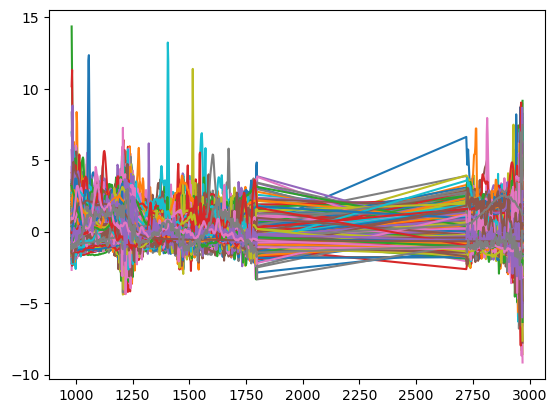

In [97]:
_ = plt.plot(passive_data_ir.iloc[:,:-7].T)#.std(1)

In [5]:
passive_data_ir = passive_data_ir.loc[["ICB" not in x for x in passive_data_ir['id']],:].reset_index(drop=True)
passive_data_raman = passive_data_raman.loc[["ICB" not in x for x in passive_data_raman['id']],:].reset_index(drop=True)


,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2965.0,2967.0,2969.0,map_x,map_y,id,background,type,polymer,label
0,1.260025,2.221031,2.402195,1.774973,0.621350,0.490222,1.087096,0.869730,-0.395493,-1.058878,...,-3.348367,-0.593594,3.785319,7456.049805,-6441.850098,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,no_background,Passive,,
1,0.401976,0.469622,0.530963,0.594825,0.662193,0.730060,0.788306,0.840454,0.896891,0.951540,...,-0.961706,-0.963350,-0.962757,7469.549805,-6414.450195,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,no_background,Passive,,
2,2.943065,-0.769979,-1.185707,-1.564923,-1.689179,-0.531970,0.711697,1.301113,0.264298,-0.488856,...,-4.548228,-4.049482,-2.617706,7475.649902,-6352.500000,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
3,-0.583662,-0.370041,-0.338847,-0.405449,-0.427099,-0.493467,-0.616169,-0.594944,-0.379421,-0.388104,...,2.281500,2.828226,3.015233,7442.500000,-6335.500000,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,no_background,Passive,,
4,1.298408,1.416424,1.530311,1.631763,1.725992,1.855778,2.700818,3.789578,4.348506,4.805948,...,-0.784927,-0.784946,-0.785304,7444.350098,-6294.049805,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,no_background,Passive,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
503,-0.086472,-0.041544,-0.018837,-0.103135,-0.069867,-0.123791,-0.122939,-0.042615,-0.050593,-0.119236,...,-1.026287,-1.396990,-1.247302,22041.349609,-7016.850098,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...,no_background,Active,,
504,-1.130889,-0.554716,-0.242449,-0.330649,0.006784,0.258411,0.248532,-0.188579,0.107501,0.012320,...,-3.860093,-6.007669,-4.968826,21853.949219,-7092.100098,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...,no_background,Active,,
505,0.632737,0.712874,0.771358,0.859226,0.952260,1.034781,1.166009,1.345598,1.423547,1.437806,...,-0.682831,-0.679193,-0.681944,21846.050781,-7122.750000,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...,no_background,Active,,
506,0.884384,0.910735,0.892774,0.900432,0.988616,1.155823,1.376016,1.638068,1.961296,2.336228,...,-1.190303,-1.032844,-0.913842,21727.949219,-7059.250000,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...,no_background,Active,,


In [16]:
passive_data_ir['school'] = [x.split('_')[7] for x in passive_data_ir['id']]

In [59]:
months = ['Mar', 'Apr', 'May', 'June', 'July', 'Aug', 'Sept', 'Oct', 'Nov', 'December']
months2 = np.array(['March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December'])

months_dict = {
    '04':'April', 
    '08':'August', 
    '12':'December'
               }

In [65]:
month_pas = np.array([months2[[y in x for y in months]][0] if z == "Passive" else '' for x, z in zip(passive_data_ir['id'], passive_data_ir['type'])])
month_act = np.array([months_dict[x.split('_')[6][4:6]] if z == "Active" else '' for x, z in zip(passive_data_ir['id'], passive_data_ir['type'])])
passive_data_ir['month'] = ''
passive_data_ir.loc[month_pas == '', 'month'] = month_act[month_pas == '']
passive_data_ir.loc[month_act == '', 'month'] = month_pas[month_act == '']

In [69]:
passive_data_ir_paired = passive_data_ir.query('id not in @ids_sat and id not in @background_ids and id not in @ids_no_signal').reset_index(drop=True)
passive_data_ir_unpaired_ram = passive_data_ir.query('(id not in @ids_sat and id not in @ids_no_signal) and id in @background_ids').reset_index(drop=True)
passive_data_ir_unpaired_ir = passive_data_ir.query('(id in @ids_sat or id in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_ir_nopair = passive_data_ir.query('(id in @ids_sat or id in @ids_no_signal) and id in @background_ids').reset_index(drop=True)

passive_data_raman_paired = passive_data_raman.query('(id not in @ids_sat and id not in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_raman_unpaired_ram = passive_data_raman.query('(id not in @ids_sat and id not in @ids_no_signal) and id in @background_ids').reset_index(drop=True)
passive_data_raman_unpaired_ir = passive_data_raman.query('(id in @ids_sat or id in @ids_no_signal) and id not in @background_ids').reset_index(drop=True)
passive_data_raman_nopair = passive_data_raman.query('(id in @ids_sat or id in @ids_no_signal) and id in @background_ids').reset_index(drop=True)


In [75]:
directory_name = 'results/20251217'

In [77]:
pd.concat([pd.pivot(passive_data_ir_unpaired_ram.groupby(['school', 'month']).count()['id'].reset_index(),
         index='month',
         columns='school',
         values='id'),
pd.pivot(passive_data_ir_unpaired_ir.groupby(['school', 'month']).count()['id'].reset_index(),
         index='month',
         columns='school',
         values='id'),
pd.pivot(passive_data_ir_nopair.groupby(['school', 'month']).count()['id'].reset_index(),
         index='month',
         columns='school',
         values='id'),
pd.pivot(passive_data_ir_paired.groupby(['school', 'month']).count()['id'].reset_index(),
         index='month',
         columns='school',
         values='id')], axis=1)#.to_csv(directory_name+'/blank_count.csv')

school,DC,FHS,IAO,S2,S6,DC,FHS,IAO,S2,S4,S6,DC,FHS,IAO,S2,S4,S6
month,,,,,,,,,,,,,,,,,
April,NaN,NaN,NaN,NaN,3.0,NaN,7.0,NaN,NaN,NaN,2.0,NaN,11.0,NaN,NaN,NaN,46.0
August,NaN,NaN,8.0,NaN,NaN,NaN,NaN,15.0,NaN,1.0,NaN,NaN,NaN,53.0,NaN,8.0,NaN
December,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,10.0,NaN,NaN,15.0,NaN,NaN,22.0,NaN,NaN
June,NaN,2.0,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN,NaN,23.0,NaN,NaN,NaN,NaN
May,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,NaN,NaN,NaN
November,NaN,NaN,2.0,NaN,NaN,NaN,NaN,6.0,NaN,NaN,NaN,NaN,NaN,13.0,NaN,NaN,NaN
October,40.0,NaN,NaN,NaN,NaN,12.0,NaN,NaN,NaN,NaN,NaN,97.0,NaN,NaN,NaN,NaN,NaN
September,NaN,1.0,NaN,NaN,NaN,NaN,8.0,NaN,NaN,NaN,NaN,NaN,20.0,NaN,NaN,NaN,NaN
July,NaN,NaN,NaN,NaN,NaN,35.0,NaN,NaN,NaN,NaN,NaN,36.0,NaN,NaN,NaN,NaN,NaN


In [24]:
(list(passive_data_ir_unpaired_ram.query('type == "Passive"').groupby('school').count()['id']),
 list(passive_data_ir_unpaired_ir.query('type == "Passive"').groupby('school').count()['id']),
 list(passive_data_ir_nopair.query('type == "Passive"').groupby('school').count()['id']),
 list(passive_data_ir_paired.query('type == "Passive"').groupby('school').count()['id']))

([40, 3, 11], [47, 19, 22], [], [148, 54, 71])

In [23]:
(list(passive_data_ir_unpaired_ram.query('type == "Passive"').groupby('school').count()['id'])+
 list(passive_data_ir_unpaired_ir.query('type == "Passive"').groupby('school').count()['id'])+
 list(passive_data_ir_nopair.query('type == "Passive"').groupby('school').count()['id'])+
 list(passive_data_ir_paired.query('type == "Passive"').groupby('school').count()['id']))

[40, 3, 11, 47, 19, 22, 148, 54, 71]

In [18]:
print('unpaired Raman spectra: ', passive_data_ir_unpaired_ram.query('type == "Passive"').shape[0])
print('unpaired IR spectra: ', passive_data_ir_unpaired_ir.query('type == "Passive"').shape[0])
print('no pair spectra: ', passive_data_ir_nopair.query('type == "Passive"').shape[0])
print('paired spectra: ', passive_data_ir_paired.query('type == "Passive"').shape[0])

unpaired Raman spectra:  54
unpaired IR spectra:  88
no pair spectra:  0
paired spectra:  273


In [49]:
print('unpaired Raman spectra: ', passive_data_ir_unpaired_ram.query('type == "Passive"').shape[0])
print('unpaired IR spectra: ', passive_data_ir_unpaired_ir.query('type == "Passive"').shape[0])
print('no pair spectra: ', passive_data_ir_nopair.query('type == "Passive"').shape[0])
print('paired spectra: ', passive_data_ir_paired.query('type == "Passive"').shape[0])

unpaired Raman spectra:  54
unpaired IR spectra:  88
no pair spectra:  0
paired spectra:  273


In [19]:
print('unpaired Raman spectra: ', passive_data_ir_unpaired_ram.query('type == "Active"').shape[0])
print('unpaired IR spectra: ', passive_data_ir_unpaired_ir.query('type == "Active"').shape[0])
print('no pair spectra: ', passive_data_ir_nopair.query('type == "Active"').shape[0])
print('paired spectra: ', passive_data_ir_paired.query('type == "Active"').shape[0])

unpaired Raman spectra:  4
unpaired IR spectra:  13
no pair spectra:  0
paired spectra:  76


In [50]:
print('unpaired Raman spectra: ', passive_data_ir_unpaired_ram.query('type == "Active"').shape[0])
print('unpaired IR spectra: ', passive_data_ir_unpaired_ir.query('type == "Active"').shape[0])
print('no pair spectra: ', passive_data_ir_nopair.query('type == "Active"').shape[0])
print('paired spectra: ', passive_data_ir_paired.query('type == "Active"').shape[0])

unpaired Raman spectra:  4
unpaired IR spectra:  13
no pair spectra:  0
paired spectra:  76


In [102]:
passive_data_ir_unpaired_ram#.query('type == "Passive"').shape[0]

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2965.0,2967.0,2969.0,map_x,map_y,id,background,type,polymer,label
0,2.943065,-0.769979,-1.185707,-1.564923,-1.689179,-0.531970,0.711697,1.301113,0.264298,-0.488856,...,-4.548228,-4.049482,-2.617706,7475.649902,-6352.500000,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
1,-0.912222,-0.103088,0.643125,1.223479,0.184504,-1.246817,0.428652,1.792900,0.482232,-0.504298,...,1.904472,2.212177,6.409209,7653.149902,-6234.299805,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
2,0.224567,1.019806,1.357778,2.156990,2.804244,1.714209,1.117121,1.891362,0.652893,-0.990681,...,-0.318939,0.221608,2.866139,7711.700195,-6234.500000,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
3,-0.749328,0.357234,-0.103031,-1.019042,-1.289617,-0.636336,-0.244867,-0.822966,-1.053931,-0.539121,...,2.575695,7.742153,-3.193660,7409.850098,-6832.500000,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
4,0.272607,-0.089343,-0.188403,0.100796,0.778503,1.155663,0.825978,0.615351,-0.389046,-1.368628,...,0.098837,0.598867,-1.094218,7384.799805,-6824.899902,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
5,-0.577275,-0.199327,1.074254,0.663651,-0.838253,-0.704737,-0.855056,-0.844327,0.841690,1.952165,...,-2.185697,-1.988637,-1.329834,7490.649902,-6802.200195,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
6,-0.349914,-1.141375,-1.251310,0.100772,0.509020,-0.754698,-0.623422,0.900522,1.896164,0.882403,...,-2.617482,1.675178,2.039661,7302.950195,-6951.700195,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
7,-0.207121,-1.078117,-0.635461,-1.242484,-0.612804,0.541357,-0.185530,-0.557816,-0.203792,-0.089746,...,3.006005,3.189781,-0.516408,7315.899902,-6920.899902,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
8,0.342318,1.222635,-0.604163,-1.119132,-0.954897,-0.718536,0.044873,-0.116842,0.740927,1.237479,...,-3.109111,-1.518243,2.618477,7312.750000,-6914.200195,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,
9,-1.368039,-1.251547,-1.112726,-0.475094,0.187426,-0.233710,-0.080288,0.672382,1.229592,0.214203,...,-0.808399,-4.464173,-3.768294,7250.100098,-6878.750000,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,background,Passive,,


# Passive

# paired

In [15]:
passive_data_raman_paired

,602.0,604.0,606.0,608.0,610.0,612.0,614.0,616.0,618.0,620.0,...,3490.0,3492.0,3494.0,3496.0,3498.0,map_x,map_y,id,polymer,label
0,-0.767024,-0.697103,-0.455961,-0.482040,-0.723182,-0.767024,-0.767024,-0.767024,-0.767024,-0.767024,...,-0.767024,-0.767024,-0.767024,-0.767024,-0.767024,7456.049805,-6441.850098,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,,
1,-0.582501,-0.492886,-0.706213,-0.801341,-0.801341,-0.557853,-0.285048,-0.288642,-0.392838,-0.686838,...,-0.801341,-0.801341,-0.801341,-0.801341,-0.801341,7442.500000,-6335.500000,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,,
2,-0.478955,-0.646616,-0.646616,-0.646616,-0.646616,-0.646616,-0.646616,-0.646616,-0.646616,-0.646616,...,-0.646616,-0.646616,-0.646616,-0.646616,-0.646616,7446.200195,-6070.750000,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,,
3,1.335104,1.085340,0.845582,0.652501,0.496984,0.412855,0.348303,0.325172,0.311678,0.316368,...,-0.334744,-0.334744,-0.334744,-0.334744,-0.334744,7633.500000,-6066.899902,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,,
4,-0.115671,-0.074572,0.026626,0.041771,-0.012342,-0.104679,-0.198100,-0.208896,-0.230771,-0.273552,...,-0.762162,-0.762162,-0.762162,-0.762162,-0.762162,7824.700195,-6166.299805,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
344,3.091604,3.158485,3.219152,3.270946,3.109553,2.856138,2.471494,2.108713,1.809898,1.652993,...,-0.462554,-0.462554,-0.462554,-0.462554,-0.462554,22224.400391,-7034.899902,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...,,
345,2.110586,2.655078,3.159024,3.605086,3.883872,4.090453,3.849227,3.569418,3.204359,2.831699,...,-0.537998,-0.537998,-0.537998,-0.537998,-0.537998,22041.349609,-7016.850098,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...,,
346,-0.050057,-0.062572,-0.163119,-0.389339,-0.329292,-0.145678,-0.025104,0.055381,0.030928,-0.012566,...,-0.782002,-0.782002,-0.782002,-0.782002,-0.782002,21853.949219,-7092.100098,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...,,
347,2.381969,2.964572,3.276315,3.201386,3.137724,3.078926,2.712856,2.357819,2.044866,1.884556,...,-0.581304,-0.581304,-0.581304,-0.581304,-0.581304,21727.949219,-7059.250000,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...,,


In [20]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df, 
                              (passive_data_raman_paired.
                               query('type == "Passive"').
                               drop('type', axis=1).reset_index(drop=True)))

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                             calibration_set_raman,
                                             test_set_raman)



(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                              (passive_data_ir_paired.
                               query('type == "Passive"').
                               drop('type', axis=1).
                               reset_index(drop=True)))

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)

In [21]:
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(test_set_ir.iloc[:,3:]), r_min=0)

In [22]:
alpha = 0.1

In [23]:
def smx_log(X_train, X_test, labels_train, C=0.01, return_weights=False):
    
    clf = LogisticRegression(random_state=0, C=C).fit(X_train, labels_train)
    smx = clf.predict_proba(X_test)
    label_pred = clf.predict(X_test)
    if return_weights:
        return smx, clf
    
    return smx

In [24]:
# Calculate HQI for calibration set
smx_cal_ir = smx_nn(X_train_ir, X_cal_ir, label_train_ir)

# Calculate HQI for test set
smx_test_ir = smx_nn(X_train_ir, X_test_ir, label_train_ir)


smx_test_all_ir = smx_nn_all(
        X_train_ir, 
        X_test_ir, 
        label_train_ir
)

pred_flopp_df = [
    np.array(label_table_ir.iloc[np.argmax(smx_test_ir, 1),1]),
    np.max(smx_test_ir, 1),
    np.array(reference_library_ir.iloc[np.argmax(smx_test_all_ir, 0),0])
]

# Set confidence level 1 - alpha
n = smx_cal_ir.shape[0]
#alpha = 0.1
#for alpha in [alpha]:
prediction_sets_ir, qhat_ir = conform_pred(smx_cal_ir, smx_test_ir, label_cal_ir, n, alpha, cond=0)

prediction_sets_n_ir = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets_ir]
prediction_sets_size_ir = np.array([len(ps) for ps in prediction_sets_n_ir])

zero_label_ir = np.where(prediction_sets_size_ir == 0)[0]
single_label_ir = np.where(prediction_sets_size_ir == 1)[0]
mult_label_ir = np.where(prediction_sets_size_ir > 1)[0]

print('Sets with zero labels: ' + str(zero_label_ir.shape[0]))
print('Sets with one label: ' + str(single_label_ir.shape[0]))
print('Sets with >1 labels: ' + str(mult_label_ir.shape[0]))
print('Mean set size:', prediction_sets_ir.sum(1).mean())
print('Std set size:', prediction_sets_ir.sum(1).std())
print('HQI cutt off:', 1-qhat_ir)

Sets with zero labels: 0
Sets with one label: 61
Sets with >1 labels: 212
Mean set size: 3.5164835164835164
Std set size: 2.88622839953293
HQI cutt off: 0.8938658598510795


In [53]:
# Calculate HQI for calibration set
smx_cal_raman = smx_log(X_train_raman, 
                  X_cal_raman, 
                  label_train_raman, C=0.002)

# Calculate HQI for test set
smx_test_raman = smx_log(X_train_raman, 
                   X_test_raman, 
                   label_train_raman, C=0.002)

#smx_test_all = smx_nn_all(
#        X_train_raman, 
#        X_test_raman, 
#        label_train_raman
#)

#pred_slopp_df = [
#    np.array(label_table_raman.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_raman.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal_raman.shape[0]
#for alpha in [alpha]:
prediction_sets_raman, qhat_raman = conform_pred(smx_cal_raman, smx_test_raman, label_cal_raman, n, alpha, cond=0)

prediction_sets_n_raman = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets_raman]
prediction_sets_size_raman = np.array([len(ps) for ps in prediction_sets_n_raman])

zero_label_raman = np.where(prediction_sets_size_raman == 0)[0]
single_label_raman = np.where(prediction_sets_size_raman == 1)[0]
mult_label_raman = np.where(prediction_sets_size_raman > 1)[0]

print('Sets with zero labels: ' + str(zero_label_raman.shape[0]))
print('Sets with one label: ' + str(single_label_raman.shape[0]))
print('Sets with >1 labels: ' + str(mult_label_raman.shape[0]))
print('Mean set size:', prediction_sets_raman.sum(1).mean())
print('Std set size:', prediction_sets_raman.sum(1).std())
print('HQI cutt off:', 1-qhat_raman)

Sets with zero labels: 0
Sets with one label: 37
Sets with >1 labels: 236
Mean set size: 2.5714285714285716
Std set size: 1.0033955955097849
HQI cutt off: 0.09032758588127421


In [27]:
prediction_sets_raman

array([[False, False, False, ..., False, False, False],
       [False, False, False, ...,  True, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

In [28]:
prediction_sets = prediction_sets_ir + prediction_sets_raman
prediction_sets_n = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]

In [29]:
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Mean set size: 5.146520146520147
Std set size: 2.6575893081725024


In [56]:
arg_sort_hqi_ir = np.argsort(1-smx_test_ir, 1)

output_df_ir = pd.DataFrame(
    np.array(
        label_table_ir.iloc[np.argsort(1-smx_test_ir, 1).flatten(), 1]
    ).reshape(smx_test_ir.shape)
)

output_df_ir.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test_ir, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]


for i in range(smx_test_ir.shape[0]):
    #ps_size = prediction_sets.sum(1)[i]
    #output_df_ir.iloc[i, ps_size:14] = ''
    #output_df_ir.iloc[i, 14+ps_size:28] = ''
    
    idx_hqi_ir = np.array([x in prediction_sets_n[i] for j, x in enumerate(list(label_table_ir['polymer']))])[arg_sort_hqi_ir[i,:]]
    output_df_ir.loc[i, ~idx_hqi_ir] = ''
    output_df_hqi.loc[i, ~idx_hqi_ir] = ''
    

output_df_ir = pd.concat([output_df_ir, output_df_hqi], axis=1)

for i in np.unique(label_train_ir):
    poly = label_table_ir.iloc[i, 1]
    idx_label = label_train_ir == i
    idx_top_by_label = np.argmax(smx_test_all_ir[idx_label,:], 0)
    ref_id_list = np.array(reference_library_ir.loc[idx_label,:].iloc[idx_top_by_label,0])
    output_df_ir['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df_ir['id'] = test_set_ir['id']

 #= pd.read_excel('evaluation_data/Passive_MVCP_Review.csv').to_numpy().flatten()

output_df_ir#.query('id in @Passive_RamanOnly_Manual_LikelyMPs').to_csv(directory_name+'/CP_results_passive_unpaired_raman_LikelyMPs.csv')


,top_1,top_2,top_3,top_4,top_5,top_6,top_7,top_8,top_9,top_10,...,id_top_match_flopp_Polyethylene,id_top_match_flopp_Polyethylene Terephthalate,id_top_match_flopp_Polyethylene Vinyl Acetate,id_top_match_flopp_Polymethyl Methacrylate,id_top_match_flopp_Polypropylene,id_top_match_flopp_Polystyrene,id_top_match_flopp_Polyurethane,id_top_match_flopp_Polyvinyl Chloride,id_top_match_flopp_Rubber,id
0,Polypropylene,Rubber,Polyethylene Vinyl Acetate,Polyvinyl Chloride,Polyethylene,Acrylonitrile Butadiene Styrene,Polycarbonate,Polyurethane,Polyethylene Terephthalate,Polymethyl Methacrylate,...,PE 45. Black Pellet.CSV,PET 8. Black Fiber.CSV,PEVA 11. Purple Fiber.CSV,PMMA 2. Red Fiber.CSV,PP 1. White Fragment.CSV,,PU 17. Clear Fragment.CSV,PVC 7. Green Film.CSV,R 2. Black Bike Handle Cover Foam.CSV,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
1,Polypropylene,Polyethylene,,,,Polystyrene,,,Polyurethane,,...,PE 14. Green Fragment.CSV,,,,PP 7. White Bottle Cap Fragment.CSV,PS 18. Clear Fragment.CSV,PU 1. Grey Packaging Foam.CSV,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
2,Polyvinyl Chloride,Acrylic,Polyethylene Vinyl Acetate,Polyurethane,,,,,Polypropylene,,...,,,EVA 5. Green Fiber.CSV,,PP 64. Blue Fiber.CSV,,PU 21. Red Rubber Paving.CSV,PVC 22. Blue Slinky Toy Fragment.CSV,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
3,Polystyrene,Polyamide,,Polypropylene,,Polyethylene Terephthalate,,,,,...,,Polyester 17. White Fabric Bag Fiber.CSV,,,PP 38. Blue Fragment.CSV,PS 13. Pink Spoon Fragment.CSV,,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
4,Polyethylene,Polypropylene,Rubber,,,,,Polycarbonate,,,...,PE 43. Pink Fragment.CSV,,,,PP 62. Orange Fiber.CSV,,,,R 17. Grey Rubber Paving.CSV,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268,Polyethylene,Polypropylene,Rubber,,,,,Polycarbonate,,,...,PE 43. Pink Fragment.CSV,,,,PP 7. White Bottle Cap Fragment.CSV,,,,R 17. Grey Rubber Paving.CSV,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
269,Polycarbonate,,,,,,,,Polypropylene,,...,,,,,PP 64. Blue Fiber.CSV,,,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
270,Polycarbonate,,,,,,,,,Polypropylene,...,,,,,PP 64. Blue Fiber.CSV,,,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
271,Polystyrene,Polyurethane,Polypropylene,Rubber,Polyamide,Polyethylene,Acrylonitrile Butadiene Styrene,Polyvinyl Chloride,Polymethyl Methacrylate,Polyethylene Terephthalate,...,PE 34. Black Fragment.CSV,PET 10. Purple Fiber Bundle.CSV,EVA 3. Grey Foam.CSV,PMMA 1. Orange Fragment.CSV,PP 43. Green Fragment.CSV,PS 6. White Foam.CSV,PU 2. Orange Foam.CSV,PVC 23. Pink Yoga Mat Foam.CSV,R 6. Black Bike Tire Fragment.CSV,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...


In [57]:
arg_sort_hqi_raman = np.argsort(1-smx_test_raman, 1)

output_df_raman = pd.DataFrame(
    np.array(
        label_table_raman.iloc[np.argsort(1-smx_test_raman, 1).flatten(), 1]
    ).reshape(smx_test_raman.shape)
)

output_df_raman.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test_raman, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]

for i in range(smx_test_raman.shape[0]):
    #ps_size = prediction_sets.sum(1)[i]
    #output_df_raman.iloc[i, ps_size:14] = ''
    #output_df_raman.iloc[i, 14+ps_size:28] = ''
    
    idx_hqi_raman = np.array([x in prediction_sets_n[i] for j, x in enumerate(list(label_table_raman['polymer']))])[arg_sort_hqi_raman[i,:]]
    output_df_raman.loc[i, ~idx_hqi_raman] = ''
    output_df_hqi.loc[i, ~idx_hqi_raman] = ''
    
output_df_raman = pd.concat([output_df_raman, output_df_hqi], axis=1)

#for i in np.unique(label_train_raman):
#    poly = label_table_raman.iloc[i, 1]
#    idx_label = label_train_raman == i
#    idx_top_by_label = np.argmax(smx_test_all[idx_label,:], 0)
#    ref_id_list = np.array(reference_library_raman.loc[idx_label,:].iloc[idx_top_by_label,0])
#    output_df_raman['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df_raman['id'] = test_set_ir['id']

 #= pd.read_excel('evaluation_data/Passive_MVCP_Review.csv').to_numpy().flatten()

output_df_raman#.query('id in @Passive_RamanOnly_Manual_LikelyMPs').to_csv(directory_name+'/CP_results_passive_unpaired_raman_LikelyMPs.csv')


,top_1,top_2,top_3,top_4,top_5,top_6,top_7,top_8,top_9,top_10,...,top_6_hqi,top_7_hqi,top_8_hqi,top_9_hqi,top_10_hqi,top_11_hqi,top_12_hqi,top_13_hqi,top_14_hqi,id
0,Polypropylene,Polycarbonate,,Polyethylene,Polyethylene Terephthalate,Polymethyl Methacrylate,Polyurethane,Polyvinyl Chloride,Rubber,,...,0.039981,0.036471,0.028203,0.025735,,0.021624,0.014029,0.013271,0.008239,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
1,Polypropylene,Polyethylene,Polystyrene,Polycarbonate,Polyurethane,,,,,,...,,,,,,,,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
2,Polypropylene,Polycarbonate,,,,,,Polyvinyl Chloride,Polyurethane,,...,,,0.021457,0.020568,,,,0.010469,0.009447,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
3,Polypropylene,Polycarbonate,Polyethylene Terephthalate,,Polystyrene,,,,,,...,,,,,,,0.017308,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
4,Polypropylene,Polycarbonate,Polyethylene,,,,,,,Rubber,...,,,,,0.02614,,,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268,Polypropylene,Polycarbonate,,Polyethylene,,,,,Rubber,,...,,,,0.024117,,,,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
269,Polypropylene,Polycarbonate,,,,,,,,,...,,,,,,,,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
270,Polypropylene,Polycarbonate,,,,,,,,,...,,,,,,,,,,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...
271,Polypropylene,Polycarbonate,Polystyrene,Polyurethane,Polymethyl Methacrylate,Polyethylene,Polyvinyl Chloride,Polyamide,Polyethylene Terephthalate,Rubber,...,0.062367,0.046823,0.035844,0.034108,0.033439,0.019562,0.016491,0.015995,0.007549,MEC_04_054_Blank_AlSi_Passive_Oct_DC_202040916...


In [62]:
output_df_raman.to_csv(directory_name+'/CP_results_blank_paired_raman.csv')
output_df_ir.to_csv(directory_name+'/CP_results_blank_paired_ir.csv')

In [18]:
smx_all_IR = 1-np.power(smx_nn(X_train_ir, X_cal_ir, label_train_ir),1)
smx_all_Raman = 1-np.power(smx_nn(X_train_raman, X_cal_raman, label_train_raman),1)

smx_all_IR_test = 1-np.power(smx_nn(X_train_ir, X_test_ir, label_train_ir),1)
smx_all_Raman_test = 1-np.power(smx_nn(X_train_raman, X_test_raman, label_train_raman),1)


score_list = [smx_all_IR, smx_all_Raman]
score_list_test = [smx_all_IR_test, smx_all_Raman_test]

#alpha = .1
seed = 1
K = 2
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
U_list = gen_u(K, seed=0)

for i in range(K):
    #quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
    quant_smx, cal_smx, quant_labels, cal_labels, idx_quant = split_cal_test(score_list[i], label_cal_ir, cal_prop=0.1, seed=seed)
    
    val_smx, val_labels = score_list_test[i], None
    
    #y_val = list(label_table.iloc[val_labels,1])
    
    #y_val_ir = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_ir'])
    #y_val_raman = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_raman'])
    
    quant_smx_list.append(quant_smx)
    #rest_smx_list.append(rest_smx)
    cal_smx_list.append(cal_smx)
    val_smx_list.append(val_smx)

n = cal_labels.shape[0]

prediction_sets = mvcp_2(quant_smx_list, 
                                             quant_labels,   
                                             cal_smx_list,   
                                             cal_labels,   
                                             val_smx_list,   
                                             alpha,     
                                             val_labels,                 
                                             U=U_list[0])

prediction_sets_n_mvcp = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_mvcp])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 1
Sets with one label: 30
Sets with >1 labels: 242
Mean set size: 6.3699633699633695
Std set size: 4.397649097083102


In [19]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          'prection_set_ir':prediction_sets_n,
                          'prection_set_raman':prediction_sets_n_raman,
                          'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['polymer_flopp'] = pred_flopp_df[0]#np.array(pred_flopp_df[0])#['polymer_ref']
output_df['hqi_flopp'] = pred_flopp_df[1]#pred_flopp_df[1]#['hqi_ref']
output_df['id_top_match_flopp'] = pred_flopp_df[2]#np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])

output_df.to_csv(directory_name+'/CP_results_passive_blank_paired.csv')

# unpaired raman

In [30]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df,
                              (passive_data_raman_unpaired_ram.
                               query('type == "Passive"').
                               drop('type', axis=1).reset_index(drop=True))
                              )

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                 calibration_set_raman,
                                 test_set_raman)


(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                             (passive_data_ir_unpaired_ram.
                               query('type == "Passive"').
                               drop('type', axis=1).
                               reset_index(drop=True))
                              )

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)



        
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(test_set_ir.iloc[:,3:]), r_min=0)


In [31]:
# Calculate HQI for calibration set
smx_cal = smx_log(X_train_raman, 
                 X_cal_raman, 
                 label_train_raman, C=0.002)

# Calculate HQI for test set
smx_test = smx_log(X_train_raman, 
                  X_test_raman, 
                  label_train_raman, C=0.002)

#smx_test_all = smx_nn_all(
#        X_train_raman, 
#        X_test_raman, 
#        label_train_raman
#)

pred_slopp_df = [
    np.array(label_table_raman.iloc[np.argmax(smx_test, 1),1]),
    np.max(smx_test, 1),
#    np.array(reference_library_raman.iloc[np.argmax(smx_test_all, 0),0])
]


# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_raman, n, alpha, cond=0)

prediction_sets_n_raman = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_raman])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 0
Sets with one label: 3
Sets with >1 labels: 51
Mean set size: 3.4814814814814814
Std set size: 1.2132103225303112


In [34]:
output_df = pd.DataFrame(
    np.array(
        label_table_raman.iloc[np.argsort(1-smx_test, 1).flatten(), 1]
    ).reshape(smx_test.shape)
)

output_df.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]

output_df = pd.concat([output_df, output_df_hqi], axis=1)

for i in range(smx_test.shape[0]):
    ps_size = prediction_sets.sum(1)[i]
    output_df.iloc[i, ps_size:14] = ''
    output_df.iloc[i, 14+ps_size:28] = ''

#for i in np.unique(label_train_raman):
#    poly = label_table_raman.iloc[i, 1]
#    idx_label = label_train_raman == i
#    idx_top_by_label = np.argmax(smx_test_all[idx_label,:], 0)
#    ref_id_list = np.array(reference_library_raman.loc[idx_label,:].iloc[idx_top_by_label,0])
#    output_df['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df['id'] = test_set_ir['id']

#Passive_RamanOnly_Manual_LikelyMPs = pd.read_excel('evaluation_data/Passive_RamanOnly_Manual_LikelyMPs.xlsx', header=None).to_numpy().flatten()

output_df.to_csv(directory_name+'/CP_results_passive_blank_unpaired_raman.csv')


In [68]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_raman['id'],
                          #'prection_set_ir':prediction_sets_n,
                          'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

#output_df['polymer_flopp'] = pred_flopp_df[0]#np.array(pred_flopp_df[0])#['polymer_ref']
#output_df['hqi_flopp'] = pred_flopp_df[1]#pred_flopp_df[1]#['hqi_ref']
#output_df['id_top_match_flopp'] = pred_flopp_df[2]#np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
#output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])

output_df.to_csv(directory_name+'/CP_results_passive_blank_unpaired_raman.csv')

# unpaired ir

In [69]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df, 
                             (passive_data_raman_unpaired_ir.
                               query('type == "Passive"').
                               drop('type', axis=1).reset_index(drop=True))
                              )

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                 calibration_set_raman,
                                 test_set_raman)


(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                             (passive_data_ir_unpaired_ir.
                               query('type == "Passive"').
                               drop('type', axis=1).reset_index(drop=True))
                              )

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)



        
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(test_set_ir.iloc[:,3:]), r_min=0)


In [70]:
# Calculate HQI for calibration set
smx_cal = smx_nn(X_train_ir, X_cal_ir, label_train_ir)

# Calculate HQI for test set
smx_test = smx_nn(X_train_ir, X_test_ir, label_train_ir)

smx_test_all = smx_nn_all(
        X_train_ir, 
        X_test_ir, 
        label_train_ir
)

pred_flopp_df = [
    np.array(label_table_ir.iloc[np.argmax(smx_test, 1),1]),
    np.max(smx_test, 1),
    np.array(reference_library_ir.iloc[np.argmax(smx_test_all, 0),0])
]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_ir, n, alpha, cond=0)

prediction_sets_n = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 0
Sets with one label: 29
Sets with >1 labels: 59
Mean set size: 2.784090909090909
Std set size: 2.118365920598639


In [71]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          'prection_set_ir':prediction_sets_n,
                          #'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['polymer_flopp'] = pred_flopp_df[0]#np.array(pred_flopp_df[0])#['polymer_ref']
output_df['hqi_flopp'] = pred_flopp_df[1]#pred_flopp_df[1]#['hqi_ref']
output_df['id_top_match_flopp'] = pred_flopp_df[2]#np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

#output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
#output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
#output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])

output_df.to_csv(directory_name+'/CP_results_passive_blank_unpaired_ir.csv')

# Active

# paired

In [72]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df, 
                              (passive_data_raman_paired.
                               query('type == "Active"').
                               drop('type', axis=1).reset_index(drop=True)))

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                             calibration_set_raman,
                                             test_set_raman)



(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                              (passive_data_ir_paired.
                               query('type == "Active"').
                               drop('type', axis=1).
                               reset_index(drop=True)))

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)

In [73]:
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(test_set_ir.iloc[:,3:]), r_min=0)

In [74]:
# Calculate HQI for calibration set
smx_cal_ir = smx_nn(X_train_ir, X_cal_ir, label_train_ir)

# Calculate HQI for test set
smx_test_ir = smx_nn(X_train_ir, X_test_ir, label_train_ir)


smx_test_all_ir = smx_nn_all(
        X_train_ir, 
        X_test_ir, 
        label_train_ir
)

pred_flopp_df = [
    np.array(label_table_ir.iloc[np.argmax(smx_test_ir, 1),1]),
    np.max(smx_test_ir, 1),
    np.array(reference_library_ir.iloc[np.argmax(smx_test_all_ir, 0),0])
]

# Set confidence level 1 - alpha
n = smx_cal_ir.shape[0]
#alpha = 0.1
#for alpha in [alpha]:
prediction_sets_ir, qhat_ir = conform_pred(smx_cal_ir, smx_test_ir, label_cal_ir, n, alpha, cond=0)

prediction_sets_n_ir = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets_ir]
prediction_sets_size_ir = np.array([len(ps) for ps in prediction_sets_n_ir])

zero_label_ir = np.where(prediction_sets_size_ir == 0)[0]
single_label_ir = np.where(prediction_sets_size_ir == 1)[0]
mult_label_ir = np.where(prediction_sets_size_ir > 1)[0]

print('Sets with zero labels: ' + str(zero_label_ir.shape[0]))
print('Sets with one label: ' + str(single_label_ir.shape[0]))
print('Sets with >1 labels: ' + str(mult_label_ir.shape[0]))
print('Mean set size:', prediction_sets_ir.sum(1).mean())
print('Std set size:', prediction_sets_ir.sum(1).std())
print('HQI cutt off:', 1-qhat_ir)

Sets with zero labels: 0
Sets with one label: 15
Sets with >1 labels: 61
Mean set size: 3.25
Std set size: 2.666186908597923
HQI cutt off: 0.8938658598510795


In [75]:
# Calculate HQI for calibration set
smx_cal_raman = smx_log(X_train_raman, 
                  X_cal_raman, 
                  label_train_raman, C=0.002)

# Calculate HQI for test set
smx_test_raman = smx_log(X_train_raman, 
                   X_test_raman, 
                   label_train_raman, C=0.002)

#smx_test_all = smx_nn_all(
#        X_train_raman, 
#        X_test_raman, 
#        label_train_raman
#)

#pred_slopp_df = [
#    np.array(label_table_raman.iloc[np.argmax(smx_test, 1),1]),
#    np.max(smx_test, 1),
#    np.array(reference_library_raman.iloc[np.argmax(smx_test_all, 0),0])
#]

# Set confidence level 1 - alpha
n = smx_cal_raman.shape[0]
#for alpha in [alpha]:
prediction_sets_raman, qhat_raman = conform_pred(smx_cal_raman, smx_test_raman, label_cal_raman, n, alpha, cond=0)

prediction_sets_n_raman = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets_raman]
prediction_sets_size_raman = np.array([len(ps) for ps in prediction_sets_n_raman])

zero_label_raman = np.where(prediction_sets_size_raman == 0)[0]
single_label_raman = np.where(prediction_sets_size_raman == 1)[0]
mult_label_raman = np.where(prediction_sets_size_raman > 1)[0]

print('Sets with zero labels: ' + str(zero_label_raman.shape[0]))
print('Sets with one label: ' + str(single_label_raman.shape[0]))
print('Sets with >1 labels: ' + str(mult_label_raman.shape[0]))
print('Mean set size:', prediction_sets_raman.sum(1).mean())
print('Std set size:', prediction_sets_raman.sum(1).std())
print('HQI cutt off:', 1-qhat_raman)

Sets with zero labels: 0
Sets with one label: 11
Sets with >1 labels: 65
Mean set size: 2.6973684210526314
Std set size: 1.192296952172849
HQI cutt off: 0.09032758588127421


In [76]:
prediction_sets = prediction_sets_ir + prediction_sets_raman
prediction_sets_n = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]

In [77]:
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Mean set size: 4.697368421052632
Std set size: 2.5650471260783436


In [78]:
arg_sort_hqi_ir = np.argsort(1-smx_test_ir, 1)

output_df_ir = pd.DataFrame(
    np.array(
        label_table_ir.iloc[np.argsort(1-smx_test_ir, 1).flatten(), 1]
    ).reshape(smx_test_ir.shape)
)

output_df_ir.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test_ir, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]


for i in range(smx_test_ir.shape[0]):
    #ps_size = prediction_sets.sum(1)[i]
    #output_df_ir.iloc[i, ps_size:14] = ''
    #output_df_ir.iloc[i, 14+ps_size:28] = ''
    
    idx_hqi_ir = np.array([x in prediction_sets_n[i] for j, x in enumerate(list(label_table_ir['polymer']))])[arg_sort_hqi_ir[i,:]]
    output_df_ir.loc[i, ~idx_hqi_ir] = ''
    output_df_hqi.loc[i, ~idx_hqi_ir] = ''
    

output_df_ir = pd.concat([output_df_ir, output_df_hqi], axis=1)

for i in np.unique(label_train_ir):
    poly = label_table_ir.iloc[i, 1]
    idx_label = label_train_ir == i
    idx_top_by_label = np.argmax(smx_test_all_ir[idx_label,:], 0)
    ref_id_list = np.array(reference_library_ir.loc[idx_label,:].iloc[idx_top_by_label,0])
    output_df_ir['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df_ir['id'] = test_set_ir['id']

 #= pd.read_excel('evaluation_data/Passive_MVCP_Review.csv').to_numpy().flatten()

output_df_ir#.query('id in @Passive_RamanOnly_Manual_LikelyMPs').to_csv(directory_name+'/CP_results_passive_unpaired_raman_LikelyMPs.csv')


,top_1,top_2,top_3,top_4,top_5,top_6,top_7,top_8,top_9,top_10,...,id_top_match_flopp_Polyethylene,id_top_match_flopp_Polyethylene Terephthalate,id_top_match_flopp_Polyethylene Vinyl Acetate,id_top_match_flopp_Polymethyl Methacrylate,id_top_match_flopp_Polypropylene,id_top_match_flopp_Polystyrene,id_top_match_flopp_Polyurethane,id_top_match_flopp_Polyvinyl Chloride,id_top_match_flopp_Rubber,id
0,Rubber,Polyurethane,Polypropylene,Polyethylene,Polystyrene,Polyvinyl Chloride,,,,,...,PE 34. Black Fragment.CSV,,,,PP 43. Green Fragment.CSV,PS 9. White Foam.CSV,PU 21. Red Rubber Paving.CSV,PVC 22. Blue Slinky Toy Fragment.CSV,R 4. Black Bridgestone Tire Fragment.CSV,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
1,Polycarbonate,,,,,,,,Polypropylene,,...,,,,,PP 64. Blue Fiber.CSV,,,,,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
2,Rubber,Polycarbonate,Polyurethane,Polypropylene,,,,,,,...,,,,,PP 64. Blue Fiber.CSV,PS 3. Blue Foam.CSV,PU 19. Blue Raincoat Fiber.CSV,,R 13. Pink Rubber Fragment.CSV,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
3,Polycarbonate,,,,,,,,,Polypropylene,...,,,,,PP 64. Blue Fiber.CSV,,,,,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
4,Polyurethane,Rubber,,,Polycarbonate,,,Polystyrene,,Polypropylene,...,,,,,PP 3. Yellow Fragment.CSV,PS 3. Blue Foam.CSV,PU 19. Blue Raincoat Fiber.CSV,,R 4. Black Bridgestone Tire Fragment.CSV,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,Polyvinyl Chloride,Cellulose Acetate,Polyurethane,Rubber,,Polypropylene,,,Polycarbonate,,...,,,,,PP 3. Yellow Fragment.CSV,,PU 21. Red Rubber Paving.CSV,PVC 22. Blue Slinky Toy Fragment.CSV,R 14. Green Rubber Fragment.CSV,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...
72,Polyurethane,Rubber,Polypropylene,,,,,,,,...,,,,,PP 43. Green Fragment.CSV,,PU 7. Yellow Packaging Foam.CSV,,R 4. Black Bridgestone Tire Fragment.CSV,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...
73,Polyurethane,Polymethyl Methacrylate,Polycarbonate,Polyethylene Terephthalate,Polyvinyl Chloride,Rubber,,,,,...,PE 34. Black Fragment.CSV,PET 11. Blue Fiber Bundle.CSV,,PMMA 1. Orange Fragment.CSV,PP 64. Blue Fiber.CSV,PS 6. White Foam.CSV,PU 14. Black Tennis Racket Grip Fragment.CSV,PVC 5. White Foam.CSV,R 8. White Bike Tire Fragment.CSV,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...
74,Polyurethane,,,,,Polypropylene,,,,,...,,,,,PP 43. Green Fragment.CSV,,PU 21. Red Rubber Paving.CSV,,,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...


In [79]:
arg_sort_hqi_raman = np.argsort(1-smx_test_raman, 1)

output_df_raman = pd.DataFrame(
    np.array(
        label_table_raman.iloc[np.argsort(1-smx_test_raman, 1).flatten(), 1]
    ).reshape(smx_test_raman.shape)
)

output_df_raman.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test_raman, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]

for i in range(smx_test_raman.shape[0]):
    #ps_size = prediction_sets.sum(1)[i]
    #output_df_raman.iloc[i, ps_size:14] = ''
    #output_df_raman.iloc[i, 14+ps_size:28] = ''
    
    idx_hqi_raman = np.array([x in prediction_sets_n[i] for j, x in enumerate(list(label_table_raman['polymer']))])[arg_sort_hqi_raman[i,:]]
    output_df_raman.loc[i, ~idx_hqi_raman] = ''
    output_df_hqi.loc[i, ~idx_hqi_raman] = ''
    
output_df_raman = pd.concat([output_df_raman, output_df_hqi], axis=1)

#for i in np.unique(label_train_raman):
#    poly = label_table_raman.iloc[i, 1]
#    idx_label = label_train_raman == i
#    idx_top_by_label = np.argmax(smx_test_all[idx_label,:], 0)
#    ref_id_list = np.array(reference_library_raman.loc[idx_label,:].iloc[idx_top_by_label,0])
#    output_df_raman['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df_raman['id'] = test_set_ir['id']

 #= pd.read_excel('evaluation_data/Passive_MVCP_Review.csv').to_numpy().flatten()

output_df_raman#.query('id in @Passive_RamanOnly_Manual_LikelyMPs').to_csv(directory_name+'/CP_results_passive_unpaired_raman_LikelyMPs.csv')


,top_1,top_2,top_3,top_4,top_5,top_6,top_7,top_8,top_9,top_10,...,top_6_hqi,top_7_hqi,top_8_hqi,top_9_hqi,top_10_hqi,top_11_hqi,top_12_hqi,top_13_hqi,top_14_hqi,id
0,Polystyrene,Polypropylene,Polycarbonate,Polyurethane,Polyvinyl Chloride,Polyethylene,,,Rubber,,...,0.074742,,,0.03911,,,,,,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
1,Polypropylene,Polycarbonate,,,,,,,,,...,,,,,,,,,,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
2,Polystyrene,Polypropylene,Polycarbonate,Polyurethane,,,,,Rubber,,...,,,,0.039372,,,,,,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
3,Polypropylene,Polycarbonate,,,,,,,,,...,,,,,,,,,,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
4,Polypropylene,Polycarbonate,Polystyrene,Polyurethane,,,,,Rubber,,...,,,,0.030904,,,,,,MEC_04_054_Blank_AlSi_Active_20240808_S4_20250...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,Polypropylene,Polycarbonate,,,,Polyvinyl Chloride,,Cellulose Acetate,,,...,0.034178,,0.017251,,,0.010366,0.008246,,,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...
72,Polypropylene,,,,,,,,,,...,,,,,,0.008905,0.008117,,,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...
73,Polystyrene,Polypropylene,Polycarbonate,Polyethylene,Polyurethane,Polyvinyl Chloride,Polymethyl Methacrylate,,Rubber,Polyethylene Terephthalate,...,0.076069,0.060564,,0.053174,0.038943,,,,,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...
74,Polypropylene,Polycarbonate,,,,,,,,Polyurethane,...,,,,,0.01232,,,,,MEC_04_054_Blank_AlSi_Active_20241212_S2_20250...


In [82]:
output_df_ir.to_csv(directory_name+'/CP_results_active_blank_paired_ir.csv')
output_df_raman.to_csv(directory_name+'/CP_results_active_blank_paired_raman.csv')

In [80]:
output_df_raman.iloc[1,:]

top_1                                             Polypropylene
top_2                                             Polycarbonate
top_3                                                          
top_4                                                          
top_5                                                          
top_6                                                          
top_7                                                          
top_8                                                          
top_9                                                          
top_10                                                         
top_11                                                         
top_12                                                         
top_13                                                         
top_14                                                         
top_1_hqi                                              0.650679
top_2_hqi                               

In [81]:
output_df_ir.iloc[1,:]

top_1                                                                                     Polycarbonate
top_2                                                                                                  
top_3                                                                                                  
top_4                                                                                                  
top_5                                                                                                  
top_6                                                                                                  
top_7                                                                                                  
top_8                                                                                                  
top_9                                                                                     Polypropylene
top_10                                                          

In [30]:
smx_all_IR = 1-np.power(smx_nn(X_train_ir, X_cal_ir, label_train_ir),1)
smx_all_Raman = 1-np.power(smx_nn(X_train_raman, X_cal_raman, label_train_raman),1)

smx_all_IR_test = 1-np.power(smx_nn(X_train_ir, X_test_ir, label_train_ir),1)
smx_all_Raman_test = 1-np.power(smx_nn(X_train_raman, X_test_raman, label_train_raman),1)


score_list = [smx_all_IR, smx_all_Raman]
score_list_test = [smx_all_IR_test, smx_all_Raman_test]

#alpha = .1
seed = 1
K = 2
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
U_list = gen_u(K, seed=0)

for i in range(K):
    #quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
    quant_smx, cal_smx, quant_labels, cal_labels, idx_quant = split_cal_test(score_list[i], label_cal_ir, cal_prop=0.1, seed=seed)
    
    val_smx, val_labels = score_list_test[i], None
    
    #y_val = list(label_table.iloc[val_labels,1])
    
    #y_val_ir = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_ir'])
    #y_val_raman = np.array(notes_mix_std.loc[~idx_quant,:].loc[~idx,'polymer_raman'])
    
    quant_smx_list.append(quant_smx)
    #rest_smx_list.append(rest_smx)
    cal_smx_list.append(cal_smx)
    val_smx_list.append(val_smx)

n = cal_labels.shape[0]

prediction_sets = mvcp_2(quant_smx_list, 
                                             quant_labels,   
                                             cal_smx_list,   
                                             cal_labels,   
                                             val_smx_list,   
                                             alpha,     
                                             val_labels,                 
                                             U=U_list[0])

prediction_sets_n_mvcp = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_mvcp])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 0
Sets with one label: 4
Sets with >1 labels: 72
Mean set size: 6.065789473684211
Std set size: 4.206309566140488


In [31]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          'prection_set_ir':prediction_sets_n,
                          'prection_set_raman':prediction_sets_n_raman,
                          'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['polymer_flopp'] = pred_flopp_df[0]#np.array(pred_flopp_df[0])#['polymer_ref']
output_df['hqi_flopp'] = pred_flopp_df[1]#pred_flopp_df[1]#['hqi_ref']
output_df['id_top_match_flopp'] = pred_flopp_df[2]#np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])

output_df.to_csv(directory_name+'/CP_results_active_blank_paired.csv')

# unpaired raman

In [35]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df,
                              (passive_data_raman_unpaired_ram.
                               query('type == "Active"').
                               drop('type', axis=1).reset_index(drop=True))
                              )

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                 calibration_set_raman,
                                 test_set_raman)


(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                             (passive_data_ir_unpaired_ram.
                               query('type == "Active"').
                               drop('type', axis=1).
                               reset_index(drop=True))
                              )

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)



        
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(test_set_ir.iloc[:,3:]), r_min=0)


In [36]:
# Calculate HQI for calibration set
smx_cal = smx_log(X_train_raman, 
                 X_cal_raman, 
                 label_train_raman, C=0.002)

# Calculate HQI for test set
smx_test = smx_log(X_train_raman, 
                  X_test_raman, 
                  label_train_raman, C=0.002)

smx_test_all = smx_nn_all(
        X_train_raman, 
        X_test_raman, 
        label_train_raman
)

pred_slopp_df = [
    np.array(label_table_raman.iloc[np.argmax(smx_test, 1),1]),
    np.max(smx_test, 1),
    np.array(reference_library_raman.iloc[np.argmax(smx_test_all, 0),0])
]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_raman, n, alpha, cond=0)

prediction_sets_n_raman = [list(label_table_raman.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n_raman])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())

Sets with zero labels: 0
Sets with one label: 1
Sets with >1 labels: 3
Mean set size: 2.75
Std set size: 1.479019945774904


In [38]:
output_df = pd.DataFrame(
    np.array(
        label_table_raman.iloc[np.argsort(1-smx_test, 1).flatten(), 1]
    ).reshape(smx_test.shape)
)

output_df.columns = ['top_' + str(i+1) for i in range(14)]

output_df_hqi = pd.DataFrame(1-np.sort(1-smx_test, 1))
output_df_hqi.columns = ['top_' + str(i+1) +'_hqi' for i in range(14)]

output_df = pd.concat([output_df, output_df_hqi], axis=1)

for i in range(smx_test.shape[0]):
    ps_size = prediction_sets.sum(1)[i]
    output_df.iloc[i, ps_size:14] = ''
    output_df.iloc[i, 14+ps_size:28] = ''

#for i in np.unique(label_train_raman):
#    poly = label_table_raman.iloc[i, 1]
#    idx_label = label_train_raman == i
#    idx_top_by_label = np.argmax(smx_test_all[idx_label,:], 0)
#    ref_id_list = np.array(reference_library_raman.loc[idx_label,:].iloc[idx_top_by_label,0])
#    output_df['id_top_match_flopp_'+poly] = [x if poly in prediction_sets_n[j] else '' for j, x in enumerate(ref_id_list)]

output_df['id'] = test_set_ir['id']

#Passive_RamanOnly_Manual_LikelyMPs = pd.read_excel('evaluation_data/Passive_RamanOnly_Manual_LikelyMPs.xlsx', header=None).to_numpy().flatten()

output_df.to_csv(directory_name+'/CP_results_active_blank_unpaired_raman.csv')


In [85]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_raman['id'],
                          #'prection_set_ir':prediction_sets_n,
                          'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

#output_df['polymer_flopp'] = pred_flopp_df[0]#np.array(pred_flopp_df[0])#['polymer_ref']
#output_df['hqi_flopp'] = pred_flopp_df[1]#pred_flopp_df[1]#['hqi_ref']
#output_df['id_top_match_flopp'] = pred_flopp_df[2]#np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])

output_df.to_csv(directory_name+'/CP_results_active_blank_unpaired_raman.csv')

# unpaired ir

In [86]:
(reference_library_raman, 
 calibration_set_raman, 
 test_set_raman, 
 label_table_raman) = gen_data_sets(slopp_df, 
                              rebecca_raman_df, 
                             (passive_data_raman_unpaired_ir.
                               query('type == "Active"').
                               drop('type', axis=1).reset_index(drop=True))
                              )

(X_train_raman, X_cal_raman, X_test_raman, 
 y_train_raman, y_cal_raman, y_test_raman, 
 label_train_raman, label_cal_raman, label_test_raman, 
 n_test_raman, wl_list_raman) = process_data(reference_library_raman,
                                 calibration_set_raman,
                                 test_set_raman)


(reference_library_ir, 
 calibration_set_ir, 
 test_set_ir, 
 label_table_ir) = gen_data_sets_ir(flopp_df, 
                              rebecca_ir_df, 
                             (passive_data_ir_unpaired_ir.
                               query('type == "Active"').
                               drop('type', axis=1).reset_index(drop=True))
                              )

(X_train_ir, X_cal_ir, X_test_ir, 
 y_train_ir, y_cal_ir, y_test_ir, 
 label_train_ir, label_cal_ir, label_test_ir, 
 n_test_ir, wl_list_ir) = process_data_ir(reference_library_ir,
                                 calibration_set_ir,
                                 test_set_ir)



        
pred_slopp_df = corr_matching(np.array(slopp_df.iloc[:,:-4]), 
                              slopp_df['polymer'], 
                              np.array(test_set_raman.iloc[:,3:]), r_min=0)

pred_flopp_df = corr_matching(np.array(flopp_df.iloc[:,:-4]), 
                              flopp_df['polymer'], 
                              np.array(test_set_ir.iloc[:,3:]), r_min=0)


In [87]:
# Calculate HQI for calibration set
smx_cal = smx_nn(X_train_ir, X_cal_ir, label_train_ir)

# Calculate HQI for test set
smx_test = smx_nn(X_train_ir, X_test_ir, label_train_ir)

smx_test_all = smx_nn_all(
        X_train_ir, 
        X_test_ir, 
        label_train_ir
)

pred_flopp_df = [
    np.array(label_table_ir.iloc[np.argmax(smx_test, 1),1]),
    np.max(smx_test, 1),
    np.array(reference_library_ir.iloc[np.argmax(smx_test_all, 0),0])
]

# Set confidence level 1 - alpha
n = smx_cal.shape[0]
alpha = 0.1
#for alpha in [alpha]:
prediction_sets, qhat = conform_pred(smx_cal, smx_test, label_cal_ir, n, alpha, cond=0)

prediction_sets_n = [list(label_table_ir.loc[ps,'polymer']) for ps in prediction_sets]
prediction_sets_size = np.array([len(ps) for ps in prediction_sets_n])

zero_label = np.where(prediction_sets_size == 0)[0]
single_label = np.where(prediction_sets_size == 1)[0]
mult_label = np.where(prediction_sets_size > 1)[0]

print('Sets with zero labels: ' + str(zero_label.shape[0]))
print('Sets with one label: ' + str(single_label.shape[0]))
print('Sets with >1 labels: ' + str(mult_label.shape[0]))
print('Mean set size:', prediction_sets.sum(1).mean())
print('Std set size:', prediction_sets.sum(1).std())


Sets with zero labels: 0
Sets with one label: 6
Sets with >1 labels: 7
Mean set size: 1.6153846153846154
Std set size: 0.6249260311258431


In [88]:
output = [prediction_sets_n[i][0] if i in single_label else 
              '--outlier--' if i in zero_label else 
              '--manual check!--' for i in range(label_test_ir.shape[0])]
output_df = pd.DataFrame({'id':test_set_ir['id'],
                          'prection_set_ir':prediction_sets_n,
                          #'prection_set_raman':prediction_sets_n_raman,
                          #'prection_set_mvcp':prediction_sets_n_mvcp,
                              #'output':output
                              })

output_df['polymer_flopp'] = pred_flopp_df[0]#np.array(pred_flopp_df[0])#['polymer_ref']
output_df['hqi_flopp'] = pred_flopp_df[1]#pred_flopp_df[1]#['hqi_ref']
output_df['id_top_match_flopp'] = pred_flopp_df[2]#np.array(flopp_df.iloc[np.array(pred_flopp_df[0].index),-1])

#output_df['polymer_slopp'] = pred_slopp_df[0]#np.array(pred_slopp_df[0])#['polymer_ref']
#output_df['hqi_slopp'] = pred_slopp_df[1]#pred_slopp_df[1]#['hqi_ref']
#output_df['id_top_match_slopp'] = pred_slopp_df[2]#np.array(slopp_df.iloc[np.array(pred_slopp_df[0].index),-1])

output_df.to_csv(directory_name+'/CP_results_active_blank_unpaired_ir.csv')
